# Lab 02 — ANN & Deep Learning

**Regression Models, Logistic Regression, and Activation Functions — with CPU/GPU Training**

This lab builds directly on the ideas of the previous session (Linear Regression from
scratch) and extends them to cover the three topics from tomorrow's lecture:

1. **Regression models** — several different ways to model a continuous target, from a
   from-scratch linear model to a small neural network.
2. **Logistic Regression** — the foundational algorithm for binary classification.
3. **Activation functions** — the nonlinear building blocks that let neural networks learn
   more than straight lines.

We will also show, throughout, how to write PyTorch code that runs **identically on CPU and
GPU**, and benchmark the difference.

By the end of this lab you will have trained **5 regression models** and used **7 activation
functions**, and you will understand how they connect to logistic regression and deep
learning more broadly.


# 1. Introduction

## 1.1 Recap: Supervised Learning

**Supervised learning** trains a model on labeled examples $(X, y)$ so that it learns a
mapping $f(X) \approx y$. There are two broad families:

- **Regression** — $y$ is continuous (house price, temperature, salary).
- **Classification** — $y$ is categorical (spam / not spam, disease / no disease).

Last lab we built a **Linear Regression** model from scratch for a regression problem
(California Housing). Today we go further in three directions.

## 1.2 Why More Than One Regression Model?

Linear Regression assumes the relationship between features and target is a straight line
(or hyperplane). Real data is rarely that simple. In this lab you will implement and compare:

| # | Model | Key idea |
|---|-------|----------|
| 1 | Linear Regression (from scratch) | $\hat{y} = Xw + b$, manual gradients |
| 2 | Linear Regression (`nn.Linear`) | Same model, PyTorch's built-in layer + optimizer |
| 3 | Polynomial Regression | Linear model on *expanded* (squared, interaction) features |
| 4 | Ridge Regression (L2-regularized) | Linear model with a penalty on large weights |
| 5 | MLP Regression (neural network) | Multiple layers + a nonlinear activation function |

## 1.3 Why Logistic Regression?

**Logistic Regression** is the classification counterpart of linear regression. Instead of
predicting a raw number, it predicts a **probability** that an example belongs to class 1,
by squashing a linear combination of features through the **sigmoid** activation function:

$$
\hat{p} = \sigma(Xw + b) = \frac{1}{1 + e^{-(Xw+b)}}
$$

Despite the name, it is a **classification** algorithm, not a regression algorithm — the
"regression" refers to the linear combination $Xw+b$ used internally.

## 1.4 Why Activation Functions?

If you stack multiple linear layers with **no** nonlinearity between them, the whole network
collapses mathematically into a single linear layer — depth buys you nothing. **Activation
functions** are what let deep networks approximate complex, curved, non-linear relationships.
Every activation function in this lab (sigmoid included) is one such nonlinearity.

## 1.5 Learning Objectives

By the end of this lab you should be able to:

1. Implement and compare at least **five different regression models** on the same dataset.
2. Explain what regularization (Ridge / L2) and polynomial feature expansion do to a linear
   model, and why an MLP with an activation function is strictly more expressive.
3. Implement **Logistic Regression** from scratch and using `torch.nn`, and evaluate it with
   classification metrics (accuracy, precision, recall, F1, ROC-AUC).
4. Describe, plot, and use at least **seven activation functions**: Sigmoid, Tanh, ReLU,
   Leaky ReLU, ELU, GELU, and Softmax.
5. Write PyTorch code that automatically detects and runs on **CPU or GPU**, and explain the
   performance difference.


# 2. Setup: Libraries and Device (CPU vs GPU)

## 2.1 Why Device Matters

PyTorch tensors and models live on a **device** — either the **CPU** (always available) or a
**GPU** (much faster for large matrix multiplications, if one is available, e.g. a CUDA GPU
on Colab). Every tensor and model involved in a computation must be on the **same** device,
or PyTorch will raise an error.

The standard, portable pattern is:

```python
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
X = X.to(device)
```

This way the exact same code runs on a laptop with no GPU **and** on a Colab GPU runtime,
without any changes. We will use this pattern for every model in this lab.

> **Colab tip:** Runtime → Change runtime type → Hardware accelerator → GPU (T4), then
> re-run the imports cell below.


In [1]:
# import NumPy for numerical array operations
import numpy as np
# import pandas for loading and manipulating tabular data
import pandas as pd
# import matplotlib for plotting charts
import matplotlib.pyplot as plt
# import seaborn for nicer statistical plots
import seaborn as sns
# import time to measure how long code takes to run
import time

# import PyTorch, the deep learning framework used in this lab
import torch
# import the neural network module (layers, losses, etc.)
import torch.nn as nn
# import functional API for activation functions and other stateless ops
import torch.nn.functional as F
# import dataset/dataloader helpers to batch and shuffle data
from torch.utils.data import TensorDataset, DataLoader

# import the two datasets used in this lab: housing (regression) and breast cancer (classification)
from sklearn.datasets import fetch_california_housing, load_breast_cancer
# import function to split data into train/val/test sets
from sklearn.model_selection import train_test_split
# import feature scaling and polynomial feature expansion tools
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
# import metrics used to evaluate regression and classification models
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, roc_auc_score
)

# Reproducibility
# set a fixed seed value so random operations are repeatable
SEED = 42
# seed NumPy's random number generator
np.random.seed(SEED)
# seed PyTorch's random number generator
torch.manual_seed(SEED)

# apply a clean whitegrid style to all seaborn/matplotlib plots
sns.set_style("whitegrid")
# increase the default plot resolution for clearer figures
plt.rcParams["figure.dpi"] = 100

# ---- Device setup: works on CPU-only machines AND GPU machines ----
# choose GPU if available, otherwise fall back to CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# confirm that all libraries loaded without error
print("Libraries imported successfully.")
# print the installed PyTorch version
print("PyTorch version:", torch.__version__)
# print whether a CUDA-capable GPU is available
print("CUDA available:", torch.cuda.is_available())
# print which device (CPU or GPU) will be used for training
print("Using device:", device)
# if a GPU is available, print its name
if torch.cuda.is_available():
    # print the name of the detected GPU
    print("GPU name:", torch.cuda.get_device_name(0))


Libraries imported successfully.
PyTorch version: 2.14.0+cpu
CUDA available: False
Using device: cpu


## 2.2 Quick CPU vs GPU Benchmark

Before we build any models, let's see *why* device matters. We multiply two large matrices
on the CPU and (if available) on the GPU, and compare the time taken. GPUs are built for
exactly this kind of large, parallel matrix multiplication.

In [2]:
def benchmark_matmul(device_name, size=2048, n_repeats=5):
    dev = torch.device(device_name)
    a = torch.randn(size, size, device=dev)
    b = torch.randn(size, size, device=dev)

    # Warm-up (important for GPU: first call includes setup/compilation cost)
    _ = a @ b
    if dev.type == "cuda":
        torch.cuda.synchronize()

    start = time.time()
    for _ in range(n_repeats):
        c = a @ b
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elapsed = (time.time() - start) / n_repeats
    return elapsed

cpu_time = benchmark_matmul("cpu")
print(f"CPU  : {cpu_time*1000:.2f} ms per {2048}x{2048} matmul")

if torch.cuda.is_available():
    gpu_time = benchmark_matmul("cuda")
    print(f"GPU  : {gpu_time*1000:.2f} ms per {2048}x{2048} matmul")
    print(f"Speedup: {cpu_time / gpu_time:.1f}x faster on GPU")
else:
    print("No GPU available in this runtime — skip GPU benchmark.")
    print("(On Colab: Runtime > Change runtime type > GPU, then re-run.)")


CPU  : 39.75 ms per 2048x2048 matmul
No GPU available in this runtime — skip GPU benchmark.
(On Colab: Runtime > Change runtime type > GPU, then re-run.)


# 3. Activation Functions

## 3.1 What Is an Activation Function?

An activation function $\phi$ is a (usually nonlinear) function applied element-wise to the
output of a linear layer:

$$
z = Xw + b \qquad \qquad a = \phi(z)
$$

Without $\phi$, stacking linear layers is pointless: $W_2(W_1x + b_1) + b_2$ is still just a
linear function of $x$. The activation function is what gives a network the ability to
represent curves, decision boundaries, and complex patterns.

Below we implement, plot, and describe **seven** activation functions commonly used in deep
learning. For each one we note: the formula, its output range, and a typical use case.

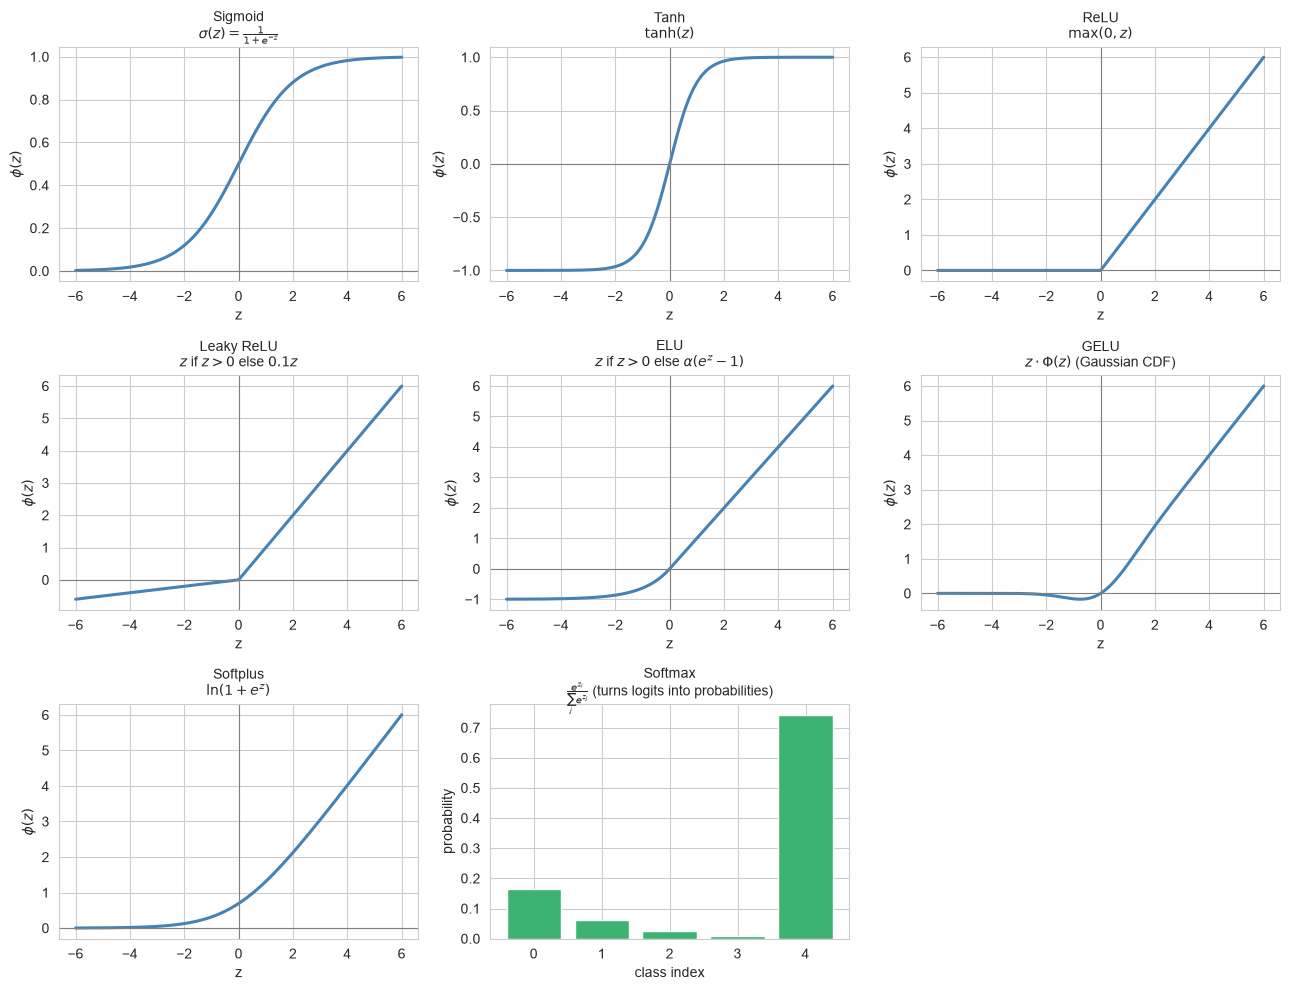

Softmax output (sums to 1): [0.165 0.061 0.025 0.008 0.741] sum = 1.0


In [3]:
z = torch.linspace(-6, 6, 400)

activations = {
    "Sigmoid":    (torch.sigmoid(z),                         r"$\sigma(z)=\frac{1}{1+e^{-z}}$"),
    "Tanh":       (torch.tanh(z),                             r"$\tanh(z)$"),
    "ReLU":       (F.relu(z),                                 r"$\max(0, z)$"),
    "Leaky ReLU": (F.leaky_relu(z, negative_slope=0.1),       r"$z$ if $z>0$ else $0.1z$"),
    "ELU":        (F.elu(z, alpha=1.0),                       r"$z$ if $z>0$ else $\alpha(e^z-1)$"),
    "GELU":       (F.gelu(z),                                 r"$z \cdot \Phi(z)$ (Gaussian CDF)"),
    "Softplus":   (F.softplus(z),                             r"$\ln(1+e^{z})$"),
}

fig, axes = plt.subplots(3, 3, figsize=(13, 10))
axes = axes.flatten()

for i, (name, (values, formula)) in enumerate(activations.items()):
    ax = axes[i]
    ax.plot(z.numpy(), values.numpy(), linewidth=2.2, color="steelblue")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_title(f"{name}\n{formula}", fontsize=10)
    ax.set_xlabel("z")
    ax.set_ylabel(r"$\phi(z)$")

# Softmax is special: it acts on a VECTOR, not element-wise, so plot it separately
logits = torch.tensor([2.0, 1.0, 0.1, -1.0, 3.5])
probs = F.softmax(logits, dim=0)
axes[7].bar(range(len(logits)), probs.numpy(), color="mediumseagreen")
axes[7].set_title("Softmax\n" + r"$\frac{e^{z_i}}{\sum_j e^{z_j}}$ (turns logits into probabilities)", fontsize=10)
axes[7].set_xlabel("class index")
axes[7].set_ylabel("probability")

axes[8].axis("off")

plt.tight_layout()
plt.show()

print("Softmax output (sums to 1):", probs.numpy().round(3), "sum =", probs.sum().item())


## 3.2 Summary Table — 7 Activation Functions

| Activation | Formula | Output range | Typical use |
|---|---|---|---|
| **Sigmoid** | $\frac{1}{1+e^{-z}}$ | $(0, 1)$ | Output layer of **binary classifiers** / Logistic Regression |
| **Tanh** | $\tanh(z)$ | $(-1, 1)$ | Hidden layers (zero-centered version of sigmoid); RNNs |
| **ReLU** | $\max(0, z)$ | $[0, \infty)$ | Default choice for hidden layers in most modern networks |
| **Leaky ReLU** | $z$ if $z>0$, else $0.1z$ | $(-\infty, \infty)$ | Like ReLU but avoids "dead neurons" (zero gradient for $z<0$) |
| **ELU** | $z$ if $z>0$, else $\alpha(e^z-1)$ | $(-\alpha, \infty)$ | Smooth alternative to Leaky ReLU, can speed up convergence |
| **GELU** | $z\cdot\Phi(z)$ | $\approx(-0.17,\infty)$ | Used in Transformers (BERT, GPT) |
| **Softplus** | $\ln(1+e^z)$ | $(0, \infty)$ | Smooth approximation of ReLU |
| **Softmax** | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | $(0,1)$, sums to 1 | Output layer of **multi-class classifiers** |

**Key takeaway for today's lecture:**
- **Sigmoid** is exactly the function used by **Logistic Regression** to turn a linear score
  into a probability (Section 5).
- **ReLU / Leaky ReLU / ELU / GELU** are the ones you will use inside the **hidden layers**
  of the MLP Regression model (Section 4.6) and the MLP classifier (Section 5.6).
- **Softmax** generalizes sigmoid to more than 2 classes (not used directly in this lab, but
  good to know for future labs on multi-class classification).


# 4. Part A — Regression Models

## 4.1 Dataset: California Housing

We reuse the **California Housing Dataset** (`sklearn.datasets.fetch_california_housing`),
derived from the 1990 U.S. Census. The target is the **median house value** (in $100,000s)
for a California district, predicted from 8 numeric features (median income, house age,
average rooms, population, location, etc.).

In [4]:
# load the California Housing dataset as a pandas DataFrame
housing = fetch_california_housing(as_frame=True)
# copy the dataset's DataFrame so we can modify it freely
df = housing.frame.copy()
# store the list of feature (input) column names
feature_names = housing.feature_names
# name the target (output) column
target_name = "MedHouseVal"

# print the feature names to confirm the dataset loaded correctly
print("Features:", feature_names)
# print the number of samples (rows) in the dataset
print("Samples:", df.shape[0])
# display the first few rows of the dataset
df.head()


Features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Samples: 20640


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 4.2 Train / Validation / Test Split and Standardization

We split **before** fitting the scaler, so that information from the validation/test sets
never leaks into training (fit the scaler on the training set only, then `transform` — not
`fit_transform` — on validation/test).

In [5]:
# extract the feature columns as a NumPy array
X = df[feature_names].values
# extract the target column as a NumPy array
y = df[target_name].values

# split off 30% of the data as a temporary set, keeping 70% for training
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=SEED)
# split the temporary set in half to create separate validation and test sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=SEED)

# create a StandardScaler to standardize features (zero mean, unit variance)
scaler = StandardScaler()
# fit the scaler on the training data only, then transform it
X_train_s = scaler.fit_transform(X_train)
# transform the validation data using the scaler fit on training data (no fitting here)
X_val_s   = scaler.transform(X_val)
# transform the test data using the same fitted scaler
X_test_s  = scaler.transform(X_test)

# print the shapes of the resulting train/val/test splits
print("Train:", X_train_s.shape, " Val:", X_val_s.shape, " Test:", X_test_s.shape)

# define a helper function to convert NumPy arrays into PyTorch tensors
def to_tensor(X, y):
    # return the features as a float32 tensor and the target reshaped into a column vector
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32).view(-1, 1)

# convert the training features/targets into tensors
Xtr_t, ytr_t = to_tensor(X_train_s, y_train)
# convert the validation features/targets into tensors
Xval_t, yval_t = to_tensor(X_val_s, y_val)
# convert the test features/targets into tensors
Xte_t, yte_t = to_tensor(X_test_s, y_test)

# set the number of samples processed per training batch
BATCH_SIZE = 64
# create a DataLoader that shuffles and batches the training data
train_loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=BATCH_SIZE, shuffle=True)
# create a DataLoader for the validation data (no shuffling needed)
val_loader   = DataLoader(TensorDataset(Xval_t, yval_t), batch_size=BATCH_SIZE, shuffle=False)
# create a DataLoader for the test data (no shuffling needed)
test_loader  = DataLoader(TensorDataset(Xte_t, yte_t), batch_size=BATCH_SIZE, shuffle=False)


Train: (14448, 8)  Val: (3096, 8)  Test: (3096, 8)


## 4.3 A Shared Training Loop (Device-Agnostic)

Every model below — regression or classification, from-scratch or `nn.Module` — will reuse
this same training loop. Note the `.to(device)` calls: this is the pattern that lets the
**exact same code** run on CPU or GPU.

In [6]:
# define a generic training loop that works for both from-scratch and nn.Module models
def train_model(model_forward, params, loader, val_loader, loss_fn, lr=0.05,
                 epochs=30, device=device, is_module=False, verbose=True):
    '''Generic training loop.

    model_forward: either a torch.nn.Module (if is_module=True) or a plain function
                   f(X, params) -> predictions (for from-scratch models).
    params:        list of tensors with requires_grad=True (from-scratch models), or None
                   if is_module=True (the module holds its own parameters).
    '''
    if is_module:
        model_forward.to(device)
        optimizer = torch.optim.SGD(model_forward.parameters(), lr=lr)
    else:
        optimizer = torch.optim.SGD(params, lr=lr)

    history = {"train_loss": [], "val_loss": []}

    for epoch in range(epochs):
        # ---- training ----
        if is_module:
            model_forward.train()
        running_loss, n_batches = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            if is_module:
                preds = model_forward(xb)
            else:
                preds = model_forward(xb, params)
            loss = loss_fn(preds, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            n_batches += 1
        train_loss = running_loss / n_batches

        # ---- validation ----
        if is_module:
            model_forward.eval()
        val_running, vb = 0.0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                preds = model_forward(xb) if is_module else model_forward(xb, params)
                val_running += loss_fn(preds, yb).item()
                vb += 1
        val_loss = val_running / vb

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        if verbose and (epoch % 5 == 0 or epoch == epochs - 1):
            print(f"Epoch {epoch+1:3d}/{epochs} | train_loss={train_loss:.4f} | val_loss={val_loss:.4f}")

    return history

# decorate with no_grad since predictions don't need gradient tracking
@torch.no_grad()
def get_predictions(loader, model_forward, params=None, is_module=False, device=device):
    all_preds, all_targets = [], []
    if is_module:
        model_forward.eval()
    for xb, yb in loader:
        xb = xb.to(device)
        preds = model_forward(xb) if is_module else model_forward(xb, params)
        all_preds.append(preds.cpu().numpy())
        all_targets.append(yb.numpy())
    return np.concatenate(all_preds).ravel(), np.concatenate(all_targets).ravel()


def compute_reg_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

results = {}   # will collect {model_name: metrics_dict} for the final comparison table


## 4.4 Model 1 — Linear Regression (From Scratch)

The baseline model from the previous lab: $\hat{y} = Xw + b$, with weights initialized
manually and updated using **manual gradient descent** (via autograd for the gradient
computation, but a hand-written parameter update).

In [7]:
# seed PyTorch again so this model's initialization is reproducible
torch.manual_seed(SEED)
# determine the number of input features from the training data
n_features = X_train_s.shape[1]

# initialize the weight vector to zeros, tracking gradients for training
w1 = torch.zeros(n_features, 1, requires_grad=True, device=device)
# initialize the bias term to zero, tracking gradients for training
b1 = torch.zeros(1, requires_grad=True, device=device)
# group the weight and bias into a single parameter list
params1 = [w1, b1]

# define the forward pass for plain linear regression: y = Xw + b
def linreg_forward(x, params):
    # unpack the weight and bias from the params list
    w, b = params
    # compute and return the linear prediction
    return x @ w + b

# define the mean squared error loss function
def mse_loss(preds, targets):
    # compute the average squared difference between predictions and targets
    return torch.mean((preds - targets) ** 2)

# Manual SGD update (does NOT use torch.optim) to show the mechanics explicitly
# define a training loop that manually updates weights via gradient descent
def train_linreg_scratch(loader, val_loader, params, lr=0.05, epochs=30):
    # unpack the weight and bias tensors
    w, b = params
    # create a dictionary to store loss history
    history = {"train_loss": [], "val_loss": []}
    # loop over each training epoch
    for epoch in range(epochs):
        # initialize the running loss for this epoch
        running = 0.0
        # iterate over each batch of training data
        for xb, yb in loader:
            # move the batch to the correct device
            xb, yb = xb.to(device), yb.to(device)
            # compute predictions for this batch
            preds = linreg_forward(xb, params)
            # compute the loss for this batch
            loss = mse_loss(preds, yb)
            # backpropagate to compute gradients
            loss.backward()
            # manually update parameters without torch.optim
            with torch.no_grad():
                # update the weight using the gradient descent rule
                w -= lr * w.grad
                # update the bias using the gradient descent rule
                b -= lr * b.grad
                # reset the weight gradient to zero for the next iteration
                w.grad.zero_()
                # reset the bias gradient to zero for the next iteration
                b.grad.zero_()
            # accumulate the batch loss
            running += loss.item()
        # compute the validation loss for this epoch using the full validation set
        val_loss = mse_loss(*get_val_tensors(val_loader, params)).item()
        # record the average training loss for this epoch
        history["train_loss"].append(running / len(loader))
        # record the validation loss for this epoch
        history["val_loss"].append(val_loss)
        # periodically print training progress
        if epoch % 5 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch+1:3d}/{epochs} | train_loss={history['train_loss'][-1]:.4f} | val_loss={val_loss:.4f}")
    # return the recorded loss history
    return history

# define a helper to gather all validation data into single tensors and predict on them
def get_val_tensors(loader, params):
    # create lists to collect feature and target batches
    xs, ys = [], []
    # disable gradient tracking since this is only for evaluation
    with torch.no_grad():
        # collect every batch from the validation loader
        for xb, yb in loader:
            xs.append(xb); ys.append(yb)
        # concatenate all feature batches and move to the device
        X_all = torch.cat(xs).to(device); Y_all = torch.cat(ys).to(device)
        # compute predictions on the full validation set
        preds = linreg_forward(X_all, params)
    # return the predictions and true targets
    return preds, Y_all

# announce which model is about to be trained
print("Model 1: Linear Regression (from scratch)")
# train the from-scratch linear regression model
hist1 = train_linreg_scratch(train_loader, val_loader, params1, lr=0.01, epochs=30)

# generate predictions on the test set
preds1, targets1 = get_predictions(test_loader, linreg_forward, params1, is_module=False)
# compute and store the regression metrics for this model
results["1. Linear Reg (scratch)"] = compute_reg_metrics(targets1, preds1)
# display the metrics for this model
results["1. Linear Reg (scratch)"]


Model 1: Linear Regression (from scratch)
Epoch   1/30 | train_loss=1.1840 | val_loss=0.6088
Epoch   6/30 | train_loss=0.5316 | val_loss=0.5450
Epoch  11/30 | train_loss=0.5251 | val_loss=0.5440
Epoch  16/30 | train_loss=0.5286 | val_loss=0.5412
Epoch  21/30 | train_loss=0.5275 | val_loss=0.5411
Epoch  26/30 | train_loss=0.5271 | val_loss=0.5410
Epoch  30/30 | train_loss=0.5273 | val_loss=0.5432


{'MAE': 0.5225980877876282,
 'MSE': 0.58173006772995,
 'RMSE': np.float64(0.762712309937338),
 'R2': 0.5600653886795044}

## 4.5 Model 2 — Linear Regression (`nn.Linear` + `torch.optim`)

The same mathematical model, but built with PyTorch's built-in `nn.Linear` layer and an
`optim.SGD` optimizer instead of manual updates. This is the idiomatic way to write it and
what we will build on for every model from here on.

In [8]:
class LinearRegressionModel(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.linear = nn.Linear(n_features, 1)

    def forward(self, x):
        return self.linear(x)

torch.manual_seed(SEED)
model2 = LinearRegressionModel(n_features)

print("Model 2: Linear Regression (nn.Linear)")
hist2 = train_model(model2, None, train_loader, val_loader, mse_loss, lr=0.01, epochs=30, is_module=True)

preds2, targets2 = get_predictions(test_loader, model2, is_module=True)
results["2. Linear Reg (nn.Linear)"] = compute_reg_metrics(targets2, preds2)
results["2. Linear Reg (nn.Linear)"]


Model 2: Linear Regression (nn.Linear)
Epoch   1/30 | train_loss=1.0178 | val_loss=0.6069
Epoch   6/30 | train_loss=0.5323 | val_loss=0.5558
Epoch  11/30 | train_loss=0.5259 | val_loss=0.5504
Epoch  16/30 | train_loss=0.5286 | val_loss=0.5474
Epoch  21/30 | train_loss=0.5265 | val_loss=0.5472
Epoch  26/30 | train_loss=0.5254 | val_loss=0.5492
Epoch  30/30 | train_loss=0.5277 | val_loss=0.5474


{'MAE': 0.5202939510345459,
 'MSE': 0.5272757411003113,
 'RMSE': np.float64(0.7261375497110112),
 'R2': 0.6012466549873352}

## 4.6 Model 3 — Polynomial Regression

A **polynomial regression** model is still a *linear* model in its parameters — but it is
fit on *expanded* features (squares and pairwise products of the originals) using
`sklearn.preprocessing.PolynomialFeatures`. This lets a linear layer capture curved
relationships without adding a hidden layer or an activation function.

In [9]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_s)
X_val_poly   = poly.transform(X_val_s)
X_test_poly  = poly.transform(X_test_s)

# Re-standardize the expanded feature space (squared terms have a different scale)
poly_scaler = StandardScaler()
X_train_poly = poly_scaler.fit_transform(X_train_poly)
X_val_poly   = poly_scaler.transform(X_val_poly)
X_test_poly  = poly_scaler.transform(X_test_poly)

print("Expanded from", n_features, "to", X_train_poly.shape[1], "polynomial features")

Xtr_p, ytr_p = to_tensor(X_train_poly, y_train)
Xval_p, yval_p = to_tensor(X_val_poly, y_val)
Xte_p, yte_p = to_tensor(X_test_poly, y_test)

train_loader_p = DataLoader(TensorDataset(Xtr_p, ytr_p), batch_size=BATCH_SIZE, shuffle=True)
val_loader_p   = DataLoader(TensorDataset(Xval_p, yval_p), batch_size=BATCH_SIZE, shuffle=False)
test_loader_p  = DataLoader(TensorDataset(Xte_p, yte_p), batch_size=BATCH_SIZE, shuffle=False)

torch.manual_seed(SEED)
model3 = LinearRegressionModel(X_train_poly.shape[1])

print("\nModel 3: Polynomial Regression (degree 2)")
# Lower LR — polynomial features have a sharper loss surface and were still diverging at lr=0.001
hist3 = train_model(model3, None, train_loader_p, val_loader_p, mse_loss, lr=0.0001, epochs=50, is_module=True)

preds3, targets3 = get_predictions(test_loader_p, model3, is_module=True)
results["3. Polynomial Reg (deg 2)"] = compute_reg_metrics(targets3, preds3)
results["3. Polynomial Reg (deg 2)"]

Expanded from 8 to 44 polynomial features

Model 3: Polynomial Regression (degree 2)
Epoch   1/50 | train_loss=4.9426 | val_loss=4.6257
Epoch   6/50 | train_loss=3.3233 | val_loss=3.1843
Epoch  11/50 | train_loss=2.3506 | val_loss=2.2789
Epoch  16/50 | train_loss=1.7396 | val_loss=1.7038
Epoch  21/50 | train_loss=1.3502 | val_loss=1.3347
Epoch  26/50 | train_loss=1.0990 | val_loss=1.0957
Epoch  31/50 | train_loss=0.9353 | val_loss=0.9394
Epoch  36/50 | train_loss=0.8287 | val_loss=0.8361
Epoch  41/50 | train_loss=0.7565 | val_loss=0.7669
Epoch  46/50 | train_loss=0.7081 | val_loss=0.7198
Epoch  50/50 | train_loss=0.6806 | val_loss=0.6928


{'MAE': 0.57098388671875,
 'MSE': 0.6549409627914429,
 'RMSE': np.float64(0.8092842286807787),
 'R2': 0.5046995878219604}

## 4.7 Model 4 — Ridge Regression (L2-Regularized Linear Regression)

**Ridge Regression** adds an L2 penalty $\lambda \|w\|_2^2$ to the loss, discouraging large
weights and reducing overfitting. In PyTorch the cleanest way to add L2 regularization is
the optimizer's `weight_decay` argument, which does exactly this automatically.

In [10]:
# define a simple linear regression model using PyTorch's built-in nn.Linear layer
torch.manual_seed(SEED)
model4 = LinearRegressionModel(n_features)
optimizer4 = torch.optim.SGD(model4.parameters(), lr=0.001, weight_decay=0.05)  # lr lowered from 0.05 — was diverging
model4.to(device)

def train_ridge(model, optimizer, loader, val_loader, loss_fn, epochs=30):
    history = {"train_loss": [], "val_loss": []}
    for epoch in range(epochs):
        model.train()
        running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = model(xb)
            loss = loss_fn(preds, yb)
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # safety net against blowup
            optimizer.step()
            running += loss.item()
        model.eval()
        with torch.no_grad():
            val_preds, val_targets = [], []
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                val_preds.append(model(xb)); val_targets.append(yb)
            val_loss = loss_fn(torch.cat(val_preds), torch.cat(val_targets)).item()
        history["train_loss"].append(running / len(loader))
        history["val_loss"].append(val_loss)
        if epoch % 5 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch+1:3d}/{epochs} | train_loss={history['train_loss'][-1]:.4f} | val_loss={val_loss:.4f}")
    return history

print("Model 4: Ridge Regression")
hist4 = train_ridge(model4, optimizer4, train_loader, val_loader, mse_loss, epochs=30)

preds4, targets4 = get_predictions(test_loader, model4, is_module=True)
results["4. Ridge Regression"] = compute_reg_metrics(targets4, preds4)
results["4. Ridge Regression"]

Model 4: Ridge Regression
Epoch   1/30 | train_loss=3.8952 | val_loss=3.4454
Epoch   6/30 | train_loss=1.2841 | val_loss=1.1434
Epoch  11/30 | train_loss=0.6285 | val_loss=0.6363
Epoch  16/30 | train_loss=0.5874 | val_loss=0.6017
Epoch  21/30 | train_loss=0.5741 | val_loss=0.5878
Epoch  26/30 | train_loss=0.5652 | val_loss=0.5785
Epoch  30/30 | train_loss=0.5609 | val_loss=0.5731


{'MAE': 0.5261976718902588,
 'MSE': 0.5275141000747681,
 'RMSE': np.float64(0.7263016591436151),
 'R2': 0.6010664105415344}

## 4.8 Model 5 — MLP

Finally, a small **Multi-Layer Perceptron (MLP)**: two hidden layers with a nonlinear
**activation function** (`ReLU`, from Section 3) between them. This is the first model in
the lab that is *not* purely linear in the input features — the activation functions are
what give it the extra expressive power.

In [11]:
# define a small multi-layer perceptron (MLP) for regression with a configurable activation
class MLPRegressor(nn.Module):
     # initialize the network layers
    def __init__(self, n_features, hidden=32, activation=nn.ReLU):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden),
            activation(),
            nn.Linear(hidden, hidden // 2),
            activation(),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(SEED)
model5 = MLPRegressor(n_features, hidden=32, activation=nn.ReLU)

print("Model 5: MLP Regression (ReLU activations)")
print(model5)
hist5 = train_model(model5, None, train_loader, val_loader, mse_loss, lr=0.01, epochs=40, is_module=True)

preds5, targets5 = get_predictions(test_loader, model5, is_module=True)
results["5. MLP Regression (ReLU)"] = compute_reg_metrics(targets5, preds5)
results["5. MLP Regression (ReLU)"]


Model 5: MLP Regression (ReLU activations)
MLPRegressor(
  (net): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)
Epoch   1/40 | train_loss=1.1466 | val_loss=0.5995
Epoch   6/40 | train_loss=0.4269 | val_loss=0.4391
Epoch  11/40 | train_loss=0.3921 | val_loss=0.4070
Epoch  16/40 | train_loss=0.3700 | val_loss=0.3885
Epoch  21/40 | train_loss=0.3579 | val_loss=0.3744
Epoch  26/40 | train_loss=0.3486 | val_loss=0.3625
Epoch  31/40 | train_loss=0.3417 | val_loss=0.3583
Epoch  36/40 | train_loss=0.3354 | val_loss=0.3549
Epoch  40/40 | train_loss=0.3319 | val_loss=0.3528


{'MAE': 0.42045658826828003,
 'MSE': 0.32825803756713867,
 'RMSE': np.float64(0.5729380748101305),
 'R2': 0.7517541646957397}

## 4.9 Comparing All 5 Regression Models

In [12]:
reg_results_df = pd.DataFrame(results).T.round(4)
reg_results_df = reg_results_df.sort_values("RMSE")
reg_results_df


,MAE,MSE,RMSE,R2
5. MLP Regression (ReLU),0.4205,0.3283,0.5729,0.7518
2. Linear Reg (nn.Linear),0.5203,0.5273,0.7261,0.6012
4. Ridge Regression,0.5262,0.5275,0.7263,0.6011
1. Linear Reg (scratch),0.5226,0.5817,0.7627,0.5601
3. Polynomial Reg (deg 2),0.5710,0.6549,0.8093,0.5047


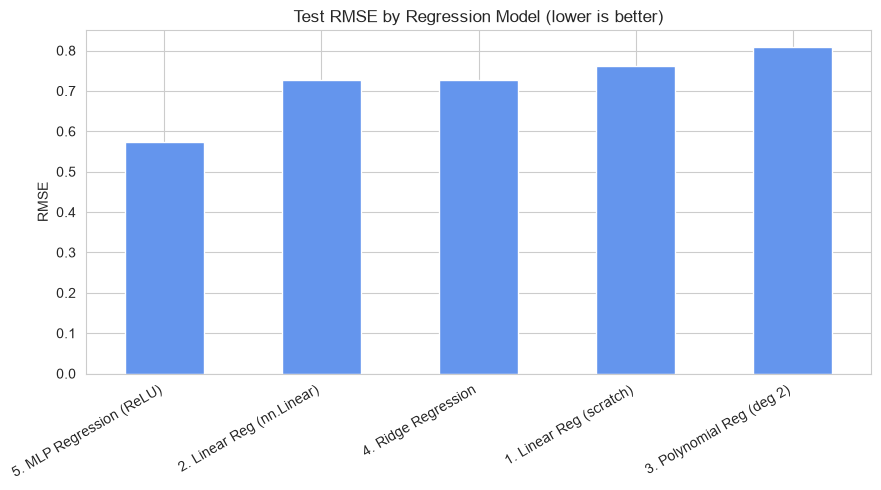

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
reg_results_df["RMSE"].plot(kind="bar", color="cornflowerblue", ax=ax)
ax.set_title("Test RMSE by Regression Model (lower is better)")
ax.set_ylabel("RMSE")
ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


**Discussion points for class:**

- Models 1 and 2 should give nearly identical results — they are the *same* mathematical
  model, just implemented two different ways (manual update vs. `torch.optim.SGD`).
- Does Polynomial Regression (Model 3) improve on plain Linear Regression? If so, the true
  relationship likely has some curvature that a straight line can't capture.
- Does Ridge Regression (Model 4) hurt or help compared to plain Linear Regression? Try
  changing `weight_decay` — very large values will underfit, very small values behave like
  plain linear regression.
- Does the MLP (Model 5) outperform all the linear approaches? If so, that is evidence the
  activation functions are adding real value by letting the model learn non-linear
  interactions between features.


# 5. Part B — Logistic Regression (Classification)

## 5.1 From Linear Regression to Logistic Regression

Logistic Regression predicts a **probability** $\hat p \in (0,1)$ that an example belongs to
class 1, by passing the linear score $z = Xw+b$ through the **Sigmoid** activation function
introduced in Section 3:

$$
z = Xw + b \qquad \hat p = \sigma(z) = \frac{1}{1+e^{-z}} \qquad \hat y = \mathbb{1}[\hat p \ge 0.5]
$$

Instead of MSE, we train with **Binary Cross-Entropy (BCE) loss**, which penalizes confident
wrong predictions much more heavily than MSE would:

$$
\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N} \Big[ y_i \log(\hat p_i) + (1-y_i)\log(1-\hat p_i) \Big]
$$

## 5.2 Dataset: Breast Cancer Wisconsin

We use `sklearn.datasets.load_breast_cancer`: 30 numeric features computed from digitized
images of breast masses, with a binary target (malignant = 0, benign = 1).

In [14]:
# load the Breast Cancer Wisconsin dataset as a pandas DataFrame
cancer = load_breast_cancer(as_frame=True)
# copy the dataset's DataFrame so we can modify it freely
df_c = cancer.frame.copy()
clf_feature_names = cancer.feature_names
# print how many features are in the dataset
print("Features:", len(clf_feature_names))
print("Samples:", df_c.shape[0])
print("Class balance:\n", df_c["target"].value_counts())
df_c.head()


Features: 30
Samples: 569
Class balance:
 target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [15]:
# extract the feature columns as a NumPy array
Xc = df_c[clf_feature_names].values
# extract the target (class label) column as a NumPy array
yc = df_c["target"].values

# split off 30% of the data as a temporary set, stratifying to preserve class balance
Xc_train, Xc_temp, yc_train, yc_temp = train_test_split(Xc, yc, test_size=0.30, random_state=SEED, stratify=yc)
# split the temporary set in half to create separate validation and test sets, again stratified
Xc_val, Xc_test, yc_val, yc_test = train_test_split(Xc_temp, yc_temp, test_size=0.50, random_state=SEED, stratify=yc_temp)

# create a StandardScaler to standardize the classification features
c_scaler = StandardScaler()
# fit the scaler on the training data only, then transform it
Xc_train_s = c_scaler.fit_transform(Xc_train)
# transform the validation data using the scaler fit on training data
Xc_val_s   = c_scaler.transform(Xc_val)
# transform the test data using the same fitted scaler
Xc_test_s  = c_scaler.transform(Xc_test)

# define a helper function to convert classification arrays into PyTorch tensors
def to_tensor_clf(X, y):
    # return the features as a float32 tensor and the labels reshaped into a column vector
    return torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32).view(-1, 1)

# convert the training features/labels into tensors
Xc_tr_t, yc_tr_t = to_tensor_clf(Xc_train_s, yc_train)
# convert the validation features/labels into tensors
Xc_val_t, yc_val_t = to_tensor_clf(Xc_val_s, yc_val)
# convert the test features/labels into tensors
Xc_te_t, yc_te_t = to_tensor_clf(Xc_test_s, yc_test)

# create a DataLoader that shuffles and batches the training data
c_train_loader = DataLoader(TensorDataset(Xc_tr_t, yc_tr_t), batch_size=32, shuffle=True)
# create a DataLoader for the validation data (no shuffling needed)
c_val_loader   = DataLoader(TensorDataset(Xc_val_t, yc_val_t), batch_size=32, shuffle=False)
# create a DataLoader for the test data (no shuffling needed)
c_test_loader  = DataLoader(TensorDataset(Xc_te_t, yc_te_t), batch_size=32, shuffle=False)

# print the shapes of the resulting train/val/test splits
print("Train:", Xc_train_s.shape, " Val:", Xc_val_s.shape, " Test:", Xc_test_s.shape)


Train: (398, 30)  Val: (85, 30)  Test: (86, 30)


## 5.3 Classification Evaluation Helper

We will reuse this function to evaluate every classifier below with **Accuracy, Precision,
Recall, F1, and ROC-AUC** — a single MSE-style metric is not enough for classification.

In [16]:
# define a helper to compute standard classification metrics from predicted probabilities
def compute_clf_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }
# create an empty dictionary to collect results for every classifier
clf_results = {}


## 5.4 Classifier 1 — Logistic Regression (From Scratch)

Manual sigmoid + manual BCE loss + manual gradient descent update, mirroring the from-scratch
linear regression model in Section 4.4.

In [17]:
# seed PyTorch for reproducible weight initialization
torch.manual_seed(SEED)
n_c_features = Xc_train_s.shape[1]
# initialize the weight vector to zeros, tracking gradients for training
wc = torch.zeros(n_c_features, 1, requires_grad=True, device=device)
# initialize the bias term to zero, tracking gradients for training
bc = torch.zeros(1, requires_grad=True, device=device)
# define the forward pass for logistic regression: sigmoid(Xw + b)
def logreg_forward(x, params):
    w, b = params
    # compute the linear score (logit)
    z = x @ w + b
    return torch.sigmoid(z)          # <-- the Sigmoid activation function from Section 3

def bce_loss(preds, targets, eps=1e-7):
    preds = torch.clamp(preds, eps, 1 - eps)   # avoid log(0)
    return -torch.mean(targets * torch.log(preds) + (1 - targets) * torch.log(1 - preds))

def train_logreg_scratch(loader, val_loader, params, lr=0.1, epochs=30):
    w, b = params
    for epoch in range(epochs):
        running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            preds = logreg_forward(xb, params)
            loss = bce_loss(preds, yb)
            loss.backward()
            with torch.no_grad():
                w -= lr * w.grad
                b -= lr * b.grad
                w.grad.zero_()
                b.grad.zero_()
            running += loss.item()
        if epoch % 5 == 0 or epoch == epochs - 1:
            print(f"Epoch {epoch+1:3d}/{epochs} | train_loss={running/len(loader):.4f}")

print("Classifier 1: Logistic Regression (from scratch)")
train_logreg_scratch(c_train_loader, c_val_loader, [wc, bc], lr=0.1, epochs=30)

probs1, ytrue1 = get_predictions(c_test_loader, logreg_forward, [wc, bc], is_module=False)
clf_results["1. Logistic Reg (scratch)"] = compute_clf_metrics(ytrue1, probs1)
clf_results["1. Logistic Reg (scratch)"]


Classifier 1: Logistic Regression (from scratch)
Epoch   1/30 | train_loss=0.3433
Epoch   6/30 | train_loss=0.1077
Epoch  11/30 | train_loss=0.0889
Epoch  16/30 | train_loss=0.0795
Epoch  21/30 | train_loss=0.0782
Epoch  26/30 | train_loss=0.0701
Epoch  30/30 | train_loss=0.0848


{'Accuracy': 0.9651162790697675,
 'Precision': 0.9636363636363636,
 'Recall': 0.9814814814814815,
 'F1': 0.9724770642201835,
 'ROC-AUC': 0.9953703703703703}

## 5.5 Classifier 2 — Logistic Regression (`nn.Linear` + `BCEWithLogitsLoss`)

The idiomatic PyTorch version. Note we use `BCEWithLogitsLoss`, which combines the Sigmoid
activation and BCE loss into a single, more **numerically stable** operation — so the model
itself outputs raw logits, and we apply `sigmoid` only when we want probabilities.

In [18]:
# define a logistic regression model using PyTorch's built-in nn.Linear layer
class LogisticRegressionModel(nn.Module):
    # initialize the model and its layers
    def __init__(self, n_features):
        # call the parent nn.Module constructor
        super().__init__()
        # define a single linear layer mapping n_features inputs to 1 output logit
        self.linear = nn.Linear(n_features, 1)

    # define the forward pass
    def forward(self, x):
        # return the raw logit (sigmoid is applied later for numerical stability)
        return self.linear(x)   # returns raw logits (no sigmoid here)

# seed PyTorch for reproducible weight initialization
torch.manual_seed(SEED)
# instantiate the logistic regression model and move it to the target device
model_c2 = LogisticRegressionModel(n_c_features).to(device)
# create an SGD optimizer for this model's parameters
optimizer_c2 = torch.optim.SGD(model_c2.parameters(), lr=0.1)
# create a loss function that combines sigmoid + BCE loss for numerical stability
bce_logits_loss = nn.BCEWithLogitsLoss()

# announce which classifier is about to be trained
print("Classifier 2: Logistic Regression (nn.Linear + BCEWithLogitsLoss)")
# loop over 30 training epochs
for epoch in range(30):
    # put the model into training mode
    model_c2.train()
    # initialize the running loss for this epoch
    running = 0.0
    # iterate over each batch of training data
    for xb, yb in c_train_loader:
        # move the batch to the correct device
        xb, yb = xb.to(device), yb.to(device)
        # compute the raw logits for this batch
        logits = model_c2(xb)
        # compute the BCE-with-logits loss for this batch
        loss = bce_logits_loss(logits, yb)
        # clear old gradients before backpropagation
        optimizer_c2.zero_grad()
        # compute gradients via backpropagation
        loss.backward()
        # update model parameters using the optimizer
        optimizer_c2.step()
        # accumulate the batch loss
        running += loss.item()
    # periodically print training progress
    if epoch % 5 == 0 or epoch == 29:
        print(f"Epoch {epoch+1:3d}/30 | train_loss={running/len(c_train_loader):.4f}")

# decorate with no_grad since predictions don't need gradient tracking
@torch.no_grad()
# define a helper to compute predicted probabilities for an nn.Module classifier
def get_probs(loader, model):
    # put the model into evaluation mode
    model.eval()
    # create lists to collect probabilities and targets across all batches
    all_probs, all_targets = [], []
    # iterate over each batch in the loader
    for xb, yb in loader:
        # move the input batch to the correct device
        xb = xb.to(device)
        # apply sigmoid to the model's raw logits to get probabilities
        probs = torch.sigmoid(model(xb))   # apply Sigmoid here to get probabilities
        # move probabilities to CPU and store as NumPy arrays
        all_probs.append(probs.cpu().numpy())
        # store the corresponding targets
        all_targets.append(yb.numpy())
    # concatenate all batches and flatten into 1D arrays
    return np.concatenate(all_probs).ravel(), np.concatenate(all_targets).ravel()

# generate predicted probabilities on the test set
probs2, ytrue2 = get_probs(c_test_loader, model_c2)
# compute and store the classification metrics for this model
clf_results["2. Logistic Reg (nn.Linear)"] = compute_clf_metrics(ytrue2, probs2)
# display the metrics for this model
clf_results["2. Logistic Reg (nn.Linear)"]


Classifier 2: Logistic Regression (nn.Linear + BCEWithLogitsLoss)
Epoch   1/30 | train_loss=0.3593
Epoch   6/30 | train_loss=0.1083
Epoch  11/30 | train_loss=0.0872
Epoch  16/30 | train_loss=0.0806
Epoch  21/30 | train_loss=0.0737
Epoch  26/30 | train_loss=0.0697
Epoch  30/30 | train_loss=0.0711


{'Accuracy': 0.9651162790697675,
 'Precision': 0.9636363636363636,
 'Recall': 0.9814814814814815,
 'F1': 0.9724770642201835,
 'ROC-AUC': 0.9936342592592593}

## 5.6 Classifier 3 — MLP Classifier (Nonlinear Logistic Regression)

Just like Section 4.8, we now add hidden layers with an activation function. The **output**
layer still ends in a single logit + sigmoid (that part *is* logistic regression); what
changes is that the score fed into the sigmoid is now a nonlinear function of the input,
learned through hidden `Tanh` activations.

In [19]:
# define a small MLP classifier with a configurable activation function
class MLPClassifier(nn.Module):
    # initialize the network layers
    def __init__(self, n_features, hidden=32, activation=nn.Tanh):
        # call the parent nn.Module constructor
        super().__init__()
        # build a sequential stack of linear layers and activations
        self.net = nn.Sequential(
            # first hidden layer: n_features -> hidden
            nn.Linear(n_features, hidden),
            # nonlinear activation after the first hidden layer
            activation(),
            # second hidden layer: hidden -> hidden // 2
            nn.Linear(hidden, hidden // 2),
            # nonlinear activation after the second hidden layer
            activation(),
            # output layer: hidden // 2 -> 1 raw logit
            nn.Linear(hidden // 2, 1),   # outputs a logit; sigmoid applied at evaluation time
        )

    # define the forward pass
    def forward(self, x):
        # pass the input through the full sequential network
        return self.net(x)

# seed PyTorch for reproducible weight initialization
torch.manual_seed(SEED)
# instantiate the MLP classifier with Tanh activations and move it to the target device
model_c3 = MLPClassifier(n_c_features, hidden=32, activation=nn.Tanh).to(device)
# create an SGD optimizer for this model's parameters
optimizer_c3 = torch.optim.SGD(model_c3.parameters(), lr=0.1)

# announce which classifier is about to be trained
print("Classifier 3: MLP Classifier (Tanh activations)")
# print the model architecture
print(model_c3)
# loop over 40 training epochs
for epoch in range(40):
    # put the model into training mode
    model_c3.train()
    # initialize the running loss for this epoch
    running = 0.0
    # iterate over each batch of training data
    for xb, yb in c_train_loader:
        # move the batch to the correct device
        xb, yb = xb.to(device), yb.to(device)
        # compute the raw logits for this batch
        logits = model_c3(xb)
        # compute the BCE-with-logits loss for this batch
        loss = bce_logits_loss(logits, yb)
        # clear old gradients before backpropagation
        optimizer_c3.zero_grad()
        # compute gradients via backpropagation
        loss.backward()
        # update model parameters using the optimizer
        optimizer_c3.step()
        # accumulate the batch loss
        running += loss.item()
    # periodically print training progress
    if epoch % 5 == 0 or epoch == 39:
        print(f"Epoch {epoch+1:3d}/40 | train_loss={running/len(c_train_loader):.4f}")

# generate predicted probabilities on the test set
probs3, ytrue3 = get_probs(c_test_loader, model_c3)
# compute and store the classification metrics for this model
clf_results["3. MLP Classifier (Tanh)"] = compute_clf_metrics(ytrue3, probs3)
# display the metrics for this model
clf_results["3. MLP Classifier (Tanh)"]


Classifier 3: MLP Classifier (Tanh activations)
MLPClassifier(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=32, bias=True)
    (1): Tanh()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): Tanh()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)
Epoch   1/40 | train_loss=0.5336
Epoch   6/40 | train_loss=0.0940
Epoch  11/40 | train_loss=0.0633
Epoch  16/40 | train_loss=0.0591
Epoch  21/40 | train_loss=0.0534
Epoch  26/40 | train_loss=0.0466
Epoch  31/40 | train_loss=0.0439
Epoch  36/40 | train_loss=0.0419
Epoch  40/40 | train_loss=0.0413


{'Accuracy': 0.9534883720930233,
 'Precision': 0.9629629629629629,
 'Recall': 0.9629629629629629,
 'F1': 0.9629629629629629,
 'ROC-AUC': 0.9913194444444444}

## 5.7 Comparing the 3 Classifiers

In [20]:
clf_results_df = pd.DataFrame(clf_results).T.round(4)
clf_results_df = clf_results_df.sort_values("ROC-AUC", ascending=False)
clf_results_df


,Accuracy,Precision,Recall,F1,ROC-AUC
1. Logistic Reg (scratch),0.9651,0.9636,0.9815,0.9725,0.9954
2. Logistic Reg (nn.Linear),0.9651,0.9636,0.9815,0.9725,0.9936
3. MLP Classifier (Tanh),0.9535,0.9630,0.9630,0.9630,0.9913


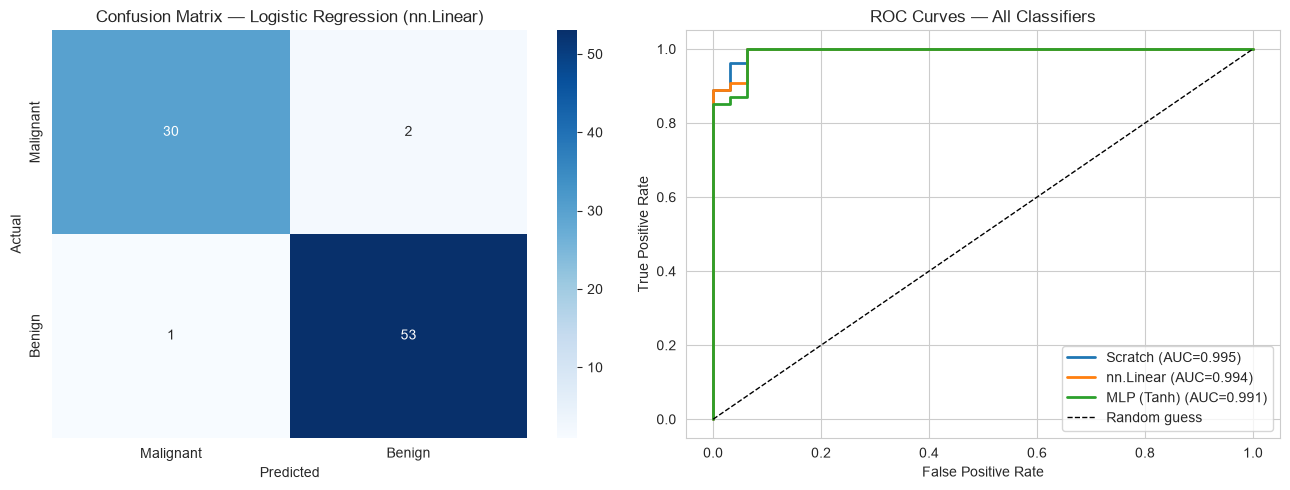

In [21]:
# create a figure with two side-by-side subplots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Confusion matrix for the best classifier (nn.Linear logistic regression) ---
best_probs, best_true = probs2, ytrue2
cm = confusion_matrix(best_true, (best_probs >= 0.5).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Malignant", "Benign"], yticklabels=["Malignant", "Benign"])
axes[0].set_title("Confusion Matrix — Logistic Regression (nn.Linear)")
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

# --- ROC curves for all 3 classifiers ---
for name, probs, ytrue in [("Scratch", probs1, ytrue1), ("nn.Linear", probs2, ytrue2), ("MLP (Tanh)", probs3, ytrue3)]:
    fpr, tpr, _ = roc_curve(ytrue, probs)
    auc = roc_auc_score(ytrue, probs)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})", linewidth=2)
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="Random guess")
axes[1].set_title("ROC Curves — All Classifiers")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.show()


## 7.3 How Everything Connects

- **Linear Regression** and **Logistic Regression** share the exact same linear core
  ($Xw+b$) — the only difference is that Logistic Regression passes it through the
  **Sigmoid** activation function and uses **BCE loss** instead of MSE.
- **Ridge Regression** shows that regularization (an L2 penalty on the weights) is a simple,
  general technique that can be added to *any* linear model with `weight_decay`.
- **Polynomial Regression** shows that you can get non-linear behavior *without* an MLP, by
  engineering non-linear features — but this doesn't scale well to many features.
- **MLP Regression** and **MLP Classifier** show that a small stack of `nn.Linear` +
  activation function layers can learn non-linear relationships automatically, without
  hand-engineering polynomial features.
- Every model in this lab — from-scratch or `nn.Module` — trained using the **same
  `device`-agnostic pattern**, so it works unchanged on CPU or GPU.


# 8. Task (To Be Submitted)

Using the models, functions, and variables you already built in this notebook, complete the
following:

**Part A — Regression models**

1. **Add a 6th regression model.** Copy the `MLPRegressor` class, rename it, and change its
   `activation` argument to `nn.GELU` or `nn.ELU` instead of `nn.ReLU`. Train it the same way
   as Model 5 and add its metrics to the `results` dictionary. Does the choice of activation
   function change the test RMSE?
2. **Tune Ridge Regression.** Retrain Model 4 with `weight_decay` set to `0.001`, `0.05`, and
   `0.5`. Report the test RMSE for each. What happens to the model as `weight_decay` grows
   very large?

**Part B — Logistic Regression**

3. **Try a different threshold.** The classifiers above use `threshold=0.5` to convert
   probability to a class label. Recompute `compute_clf_metrics` for `model_c2` at
   `threshold=0.3` and `threshold=0.7`. Explain, in your own words, how the threshold trades
   off Precision against Recall, and why this matters for a medical diagnosis dataset.
4. **Swap the activation function.** Retrain the MLP Classifier (`model_c3`) using `nn.ReLU`
   instead of `nn.Tanh` in the hidden layers. Does accuracy or ROC-AUC change?

**Part C — Activation functions**

5. **Compare gradients.** For `z = torch.linspace(-6, 6, 400)` with `requires_grad=True`,
   compute `torch.sigmoid(z).sum().backward()` and plot `z.grad`. Do the same for `ReLU` and
   `Tanh`. At which values of `z` does the Sigmoid gradient nearly vanish? Explain why this
   "vanishing gradient" problem makes Sigmoid a poor choice for *hidden* layers in deep
   networks, even though it is perfect for the *output* layer of Logistic Regression.





